In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [10]:
df=pd.read_csv("../Dataset/cleaned_data.csv")
print("missing values are=",df["AQI"].isna().sum())

missing values are= 9139


In [11]:
suspicious = df[df['AQI'] <= 10]
print(f"Rows with AQI <= 10: {len(suspicious)}")
print(suspicious[['Datetime', 'AQI']].to_string())

Rows with AQI <= 10: 30
                  Datetime   AQI
4888   2018-03-20 16:00:00   4.0
5442   2018-04-12 18:00:00   2.0
5485   2018-04-14 13:00:00   4.0
5491   2018-04-14 19:00:00   4.0
5611   2018-04-19 19:00:00   4.0
6055   2018-05-08 07:00:00   1.0
6469   2018-05-25 13:00:00   4.0
6475   2018-05-25 19:00:00   8.0
6571   2018-05-29 19:00:00   2.0
7249   2018-06-27 01:00:00  10.0
7250   2018-06-27 02:00:00   4.0
7251   2018-06-27 03:00:00   7.0
7252   2018-06-27 04:00:00   7.0
7253   2018-06-27 05:00:00   6.0
7255   2018-06-27 07:00:00   9.0
7256   2018-06-27 08:00:00   9.0
7258   2018-06-27 10:00:00   8.0
7259   2018-06-27 11:00:00   9.0
23368  2020-04-28 16:00:00  10.0
35388  2021-09-11 12:00:00   7.0
35393  2021-09-11 17:00:00  10.0
36387  2021-10-23 03:00:00   4.0
52856  2023-09-09 08:00:00   8.0
52872  2023-09-10 00:00:00  10.0
53010  2023-09-15 18:00:00   5.0
53018  2023-09-16 02:00:00  10.0
53123  2023-09-20 11:00:00   1.0
53124  2023-09-20 12:00:00   6.0
53125  2023-09-20 1

Original total rows: 55584
Sensor first recording: 2017-10-17 02:00:00
Rows after cold start removal: 53686
Missing values to handle: 7241
Missing values after cleaning: 0
Flagging 351 rows as sensor faults / interpolation artifacts

=== CLEANING SUMMARY ===
Total rows: 53686
Date range: 2017-10-17 02:00:00 to 2023-12-31 23:00:00
Missing values remaining: 0

AQI Statistics:
count    53686.000000
mean       256.485472
std        135.226493
min         40.000000
25%        135.000000
50%        237.000000
75%        368.250000
max        500.000000
Name: AQI, dtype: float64


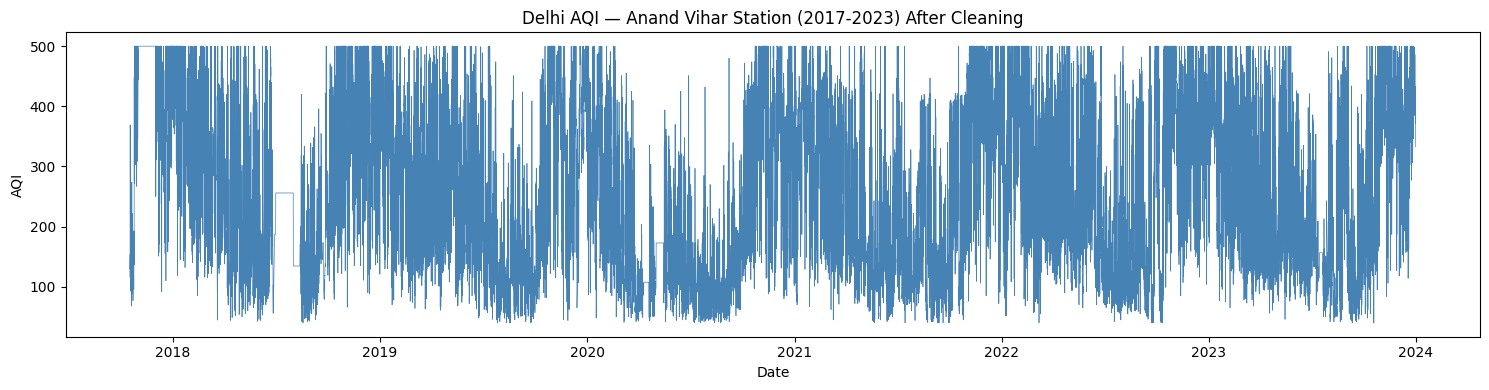


Saved as final_clean_aqi.csv


In [12]:
df['Datetime'] = pd.to_datetime(df['Datetime'])

# ── Step 2: Cold Start Fix ─────────────────────────────────────────────────
# Remove leading empty rows before sensor started recording
first_reading_row = df['AQI'].first_valid_index()
start_time = df.loc[first_reading_row, 'Datetime']

print(f"Original total rows: {len(df)}")
print(f"Sensor first recording: {start_time}")

df = df.loc[first_reading_row:].reset_index(drop=True)
print(f"Rows after cold start removal: {len(df)}")
print(f"Missing values to handle: {df['AQI'].isna().sum()}")

# ── Step 3: Layered Missing Value Strategy ─────────────────────────────────
# Layer 1: Forward fill short gaps up to 6 hours
# (sensor blips, brief outages)
df['AQI_Clean'] = df['AQI'].ffill(limit=6)

# Layer 2: Linear interpolation for medium gaps up to 24 hours
# (overnight outages, maintenance windows)
df['AQI_Clean'] = df['AQI_Clean'].interpolate(
    method='linear',
    limit=24,
    limit_direction='both'
)

# Layer 3: Monthly average for longer gaps
# (equipment failure lasting days)
df['YearMonth'] = df['Datetime'].dt.to_period('M')
monthly_avg = df.groupby('YearMonth')['AQI_Clean'].transform('mean')
df['AQI_Clean'] = df['AQI_Clean'].fillna(monthly_avg)

# Layer 4: Global mean as final fallback
df['AQI_Clean'] = df['AQI_Clean'].fillna(df['AQI_Clean'].mean())

print(f"Missing values after cleaning: {df['AQI_Clean'].isna().sum()}")

# ── Step 4: Finalize ───────────────────────────────────────────────────────
df = df.drop(columns=['AQI', 'YearMonth'])
df = df.rename(columns={'AQI_Clean': 'AQI'})

#Layer 5: dropping aqi value below 40 to make data realistic because anand vihar never expereinces this low aqi
REALISTIC_FLOOR = 40

fault_mask = df['AQI'] < REALISTIC_FLOOR
print(f"Flagging {fault_mask.sum()} rows as sensor faults / interpolation artifacts")

df.loc[fault_mask, 'AQI'] = np.nan

df['AQI'] = df['AQI'].ffill(limit=6)
df['AQI'] = df['AQI'].interpolate(method='linear', limit=24, limit_direction='both')

df['YearMonth'] = df['Datetime'].dt.to_period('M')
monthly_avg = df.groupby('YearMonth')['AQI'].transform('mean')
df['AQI'] = df['AQI'].fillna(monthly_avg)
df['AQI'] = df['AQI'].fillna(df['AQI'].mean())
df = df.drop(columns=['YearMonth'])

# ── Step 5: Verification ───────────────────────────────────────────────────
print("\n=== CLEANING SUMMARY ===")
print(f"Total rows: {len(df)}")
print(f"Date range: {df['Datetime'].min()} to {df['Datetime'].max()}")
print(f"Missing values remaining: {df['AQI'].isna().sum()}")
print(f"\nAQI Statistics:")
print(df['AQI'].describe())

# Overview plot
plt.figure(figsize=(15,4))
plt.plot(df['Datetime'], df['AQI'], linewidth=0.5, color='steelblue')
plt.title('Delhi AQI — Anand Vihar Station (2017-2023) After Cleaning')
plt.xlabel('Date')
plt.ylabel('AQI')
plt.tight_layout()
plt.show()

# Save
df.to_csv("../Dataset/final_clean_aqi.csv", index=False)
print("\nSaved as final_clean_aqi.csv")